# Assignment 2, Task 3b: Layer-wise Relevance Propagation

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 2

**Objective:** explain the predictions of the VGG16 brain tumour classifier of [notebook 05](05_vgg16_training.ipynb) with Layer-wise Relevance Propagation (LRP; Bach et al., 2015), starting from the LRP code of the provided `scripts/05_lrp.py` (deepfindr, 2021).

**Approach:**
- Load the weights saved by [notebook 05](05_vgg16_training.ipynb#sec-training); same test sets (Original, Clean\*).
- Keep the LRP rules of `05_lrp.py` (Montavon et al., 2019) and fix the issues listed in [Section 2](#sec-changes).
- Check the implementation (conservation, an independent implementation, model randomisation), then explain one typical correct case per class and contrast two classes on the main case.
- The second method, Grad-CAM, and the comparison follow in [notebook 07](07_gradcam.ipynb).

**Contents**
1. [Setup](#sec-setup)
2. [Changes from `05_lrp.py`](#sec-changes)
3. [LRP explainer](#sec-lrp)
4. [Sanity checks](#sec-checks)
5. [Local explanations](#sec-local)
6. [Class-contrastive explanation](#sec-contrast)
7. [Key takeaways](#sec-takeaways)
8. [References](#sec-references)

<a id="sec-setup"></a>

## 1. Setup

- Test sets and modality\* as in [notebook 05](05_vgg16_training.ipynb#sec-setup); predictions from the saved model.

\* Based on the author's visual judgement (not a radiologist), see [notebook 04](04_mri_eda.ipynb#sec-ct).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from captum.attr import LRP
from captum.attr._utils.lrp_rules import EpsilonRule, GammaRule
from scipy.stats import spearmanr

from brain_mri_xai import SEED
from brain_mri_xai.data import (
    CLASS_LABELS,
    CLASSES,
    annotate_test,
    flag_duplicates,
    index_images,
    load_images,
    normalise,
    split_train_validation,
)
from brain_mri_xai.explain import block_sums, lrp
from brain_mri_xai.model import (
    device,
    load_model,
    median_confidence_case,
    predict_proba,
    randomise_top_layers,
)
from brain_mri_xai.plotting import lrp_heatmap, show_image, show_lrp
from stroke_shap.plotting import FIGURE_WIDTH, label_panels, save_figure, set_theme

set_theme()
LABELS = [CLASS_LABELS[c] for c in CLASSES]
index = flag_duplicates(index_images())
test = annotate_test(index, split_train_validation(index))
assert len(test) == 394 and test["clean"].sum() == 291
test_images = load_images(test["path"])
model = load_model()  # weights saved by notebook 05, evaluation mode
probabilities = predict_proba(model, test_images)
test["predicted"] = probabilities.argmax(1)
test["confidence"] = probabilities.max(1)
test["correct"] = test["predicted"] == test["target"]

<a id="sec-changes"></a>

## 2. Changes from `05_lrp.py`

Kept: the LRP rule set and its layer ranges, max pooling treated as average pooling, and the conversion of the dense layers into convolutions (`apply_lrp_on_vgg16`). Changed:

- **Explained class:** always the top class → any class can be explained (`lrp(model, image, target)`), needed for the class-contrastive maps ([Section 6](#sec-contrast)) and for errors.
- **Pixel layer:** LRP-$\gamma$ also on the first convolution → $z^\mathcal{B}$ rule, which uses the known pixel range (black to white after normalisation) as bounds (Montavon et al., 2019); the script leaves this as "potential step 5".
- **Evaluation mode:** the script never calls `model.eval()`, so dropout stays active in the LRP forward pass → the saved model is loaded in evaluation mode; gradients are enabled only inside the LRP backward pass.
- **Heatmap:** the first colour channel, min-max rescaled to 0-1 (so zero relevance is not white and the sign is lost) → sum over the three channels, colour scale symmetric around zero ([Section 3](#sec-lrp)).
- **Packaging:** the script cells become the function `brain_mri_xai.explain.lrp` (no dependence on the script's global `device`), so notebooks 06 and 07 use the same code.

<a id="sec-lrp"></a>

## 3. LRP explainer

- LRP passes the logit of the explained class backwards, layer by layer, to the input pixels.
- Each neuron hands its relevance to the neurons below in proportion to their contribution $a_j w_{jk}$, so the basic rule (LRP-0) conserves relevance from layer to layer; LRP-$\epsilon$ and the biases absorb part of it ([Section 4](#sec-checks)).
- Different rules suit different depths (Montavon et al., 2019); the layer ranges are those of `05_lrp.py`:

| Layer index | VGG16 layers | Rule | Purpose |
|---|---|---|---|
| 0 | conv1_1 (pixels) | $z^\mathcal{B}$ | Uses the known pixel range (black to white) as bounds |
| 1-16 | conv1_2 to conv3_3 | LRP-$\gamma$ (`gamma=0.25`) | Favours positive contributions; less noisy low-level maps |
| 17-30 | conv4_1 to conv5_3 | LRP-$\epsilon$ ($\epsilon$ = 0.25 x RMS) | Absorbs weak, contradictory contributions; keeps salient paths |
| 31-37 | Dense layers (as convolutions) | LRP-0 | Basic rule; few top layers, close to the output |

- **Output:** one relevance value per input pixel, a 3 x 224 x 224 tensor summed over the three colour channels to 224 x 224; red = evidence **for** the explained class, blue = evidence **against** it, white = none.
- **Display only:** the colour scale is symmetric around zero and clipped at the 99.5th percentile of absolute relevance of each map, so a few extreme pixels do not wash out the rest; all measurements use the raw, unclipped values. A heatmap is not a tumour outline: the dataset has no tumour masks against which to validate it.

<a id="sec-checks"></a>

## 4. Sanity checks

Three checks on 40 test images drawn with `seed=2021`, each explained for its predicted class:

1. **Conservation:** pixel relevances should add up to a stable, positive share of the explained logit; below 1 by design, as LRP-$\epsilon$ and the biases absorb part of the relevance.
2. **Agreement with Captum** (Kokhlikyan et al., 2020): an independent LRP implementation with the closest rules it offers (LRP-$\gamma$, then a fixed $\epsilon$). It has no $z^\mathcal{B}$ rule and routes relevance through max pooling to the maximum only, so agreement is measured on 16 x 16-pixel blocks (Spearman rank correlation).
3. **Model randomisation** (Adebayo et al., 2018): the dense layers and the last convolutional block are re-initialised. A map that reflects the trained model should change a lot (low rank correlation with the original map); one that only traces image edges barely changes.

- **Conservation:** on average 15.3% of the explained logit reaches the pixels (median 15.0%, range 3.5-22.5%); stable and positive, but most relevance is absorbed by LRP-$\epsilon$ and the biases, so the map shows where relevance goes, not a full split of the logit.
- **Captum:** median block-level rank correlation 0.553 (range 0.128-0.761): agreement on the broad layout, not the detail, as expected from the different rules.
- **Randomisation:** after conv5 and the dense layers are re-initialised, the maps keep a median rank correlation of 0.690 with the originals. LRP fails this check: its maps partly show image structure (edges, the skull outline), a known weakness of rule sets that favour positive contributions (Sixt et al., 2020). [Notebook 07](07_gradcam.ipynb#sec-gradcam) repeats the check for Grad-CAM.
- **Cost:** median 0.350 s per image on the GPU (40 check images).

In [2]:
def captum_lrp(model: torch.nn.Module, image: torch.Tensor, target: int) -> np.ndarray:
    """Captum LRP heatmap (summed over channels) with the closest rule set to :func:`lrp`."""
    for i, layer in enumerate(model.features):
        if isinstance(layer, torch.nn.Conv2d):
            layer.rule = GammaRule(gamma=0.25) if i <= 16 else EpsilonRule(epsilon=0.25)
    relevance = LRP(model).attribute(image.unsqueeze(0).to(device()), target=target)
    return relevance[0].sum(0).detach().cpu().numpy()


N_CHECK = 40
check_ids = np.random.default_rng(SEED).choice(len(test), size=N_CHECK, replace=False)
random_model = randomise_top_layers(load_model())
checks = []
for i in check_ids:
    image, target = normalise(test_images[i]), int(test.loc[i, "predicted"])
    start = time.perf_counter()
    relevance = lrp(model, image, target)
    seconds = time.perf_counter() - start
    with torch.no_grad():
        logit = model(image.unsqueeze(0).to(device()))[0, target].item()
    ours = lrp_heatmap(relevance)
    theirs = captum_lrp(load_model(), image, target)  # fresh copy: Captum adds hooks and rules
    randomised = lrp_heatmap(lrp(random_model, image, target))
    checks.append(
        (
            relevance.sum().item() / logit,
            spearmanr(block_sums(ours), block_sums(theirs))[0],
            spearmanr(block_sums(np.abs(ours)), block_sums(np.abs(randomised)))[0],
            seconds,
        )
    )
checks = pd.DataFrame(
    checks,
    columns=[
        "Relevance sum / logit",
        "Rank correlation with Captum",
        "Rank correlation after randomisation",
        "Seconds per image",
    ],
)
checks.describe().loc[["mean", "50%", "min", "max"]].rename(index={"50%": "median"}).round(3).T

c:\Users\yeapj\miniconda3\envs\wqf7009_assignments\Lib\site-packages\captum\attr\_core\lrp.py:207: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(input_tuple)


,mean,median,min,max
Relevance sum / logit,0.153,0.150,0.035,0.225
Rank correlation with Captum,0.532,0.553,0.128,0.761
Rank correlation after randomisation,0.648,0.690,0.361,0.854
Seconds per image,0.359,0.350,0.337,0.593


<a id="sec-local"></a>

## 5. Local explanations

- **Case selection:** per class, the correctly classified Clean\* MRI\* test image with the median confidence among those images (a typical, not a best-case, example); CT scans are left out, as the model may separate them by scan type ([notebook 05](05_vgg16_training.ipynb#sec-modality)).
- Images are identified by their file name in `data/brain_mri/testing/`; each is explained for its predicted (here: true) class.
- Reading of the heatmaps below is the author's visual judgement (not a radiologist).

- **Glioma** (`glioma_tumor/image(74).jpg`, 98.6%): red on the enhancing lesion, but the skull ring is just as red.
- **Meningioma** (`meningioma_tumor/image(88).jpg`, 94.3%): strongest red along the lower edge of the large bright tumour, plus a red spot on a ventricle.
- **No Tumour** (`no_tumor/image(29).jpg`, 99.1%): red spread over the whole brain, strongest at the front; no single structure, consistent with a judgement about the overall appearance.
- **Pituitary** (`pituitary_tumor/image(94).jpg`, 95.2%): the tumour itself is mostly white (neutral); red lies below it and on scattered tissue. A correct answer without clear evidence on the tumour.
- **Artefact:** a thin red frame along the image border appears in every map; it comes from the zero padding of the first convolutions, not from the scan.

In [3]:
candidates = test[test["correct"] & test["clean"] & (test["modality"] == "MRI")]
cases = {label: median_confidence_case(candidates[candidates["label"] == label]) for label in CLASSES}
case_table = test.loc[list(cases.values()), ["label", "path", "confidence"]].assign(
    label=lambda d: d["label"].map(CLASS_LABELS),
    path=lambda d: d["path"].map(lambda p: f"{p.parent.name}/{p.name}"),
)
case_table.rename(columns={"label": "Class", "path": "File", "confidence": "Confidence"}).set_index(
    "Class"
).round(3)

,File,Confidence
Class,,
Glioma,glioma_tumor/image(74).jpg,0.986
Meningioma,meningioma_tumor/image(88).jpg,0.943
No Tumour,no_tumor/image(29).jpg,0.991
Pituitary,pituitary_tumor/image(94).jpg,0.952


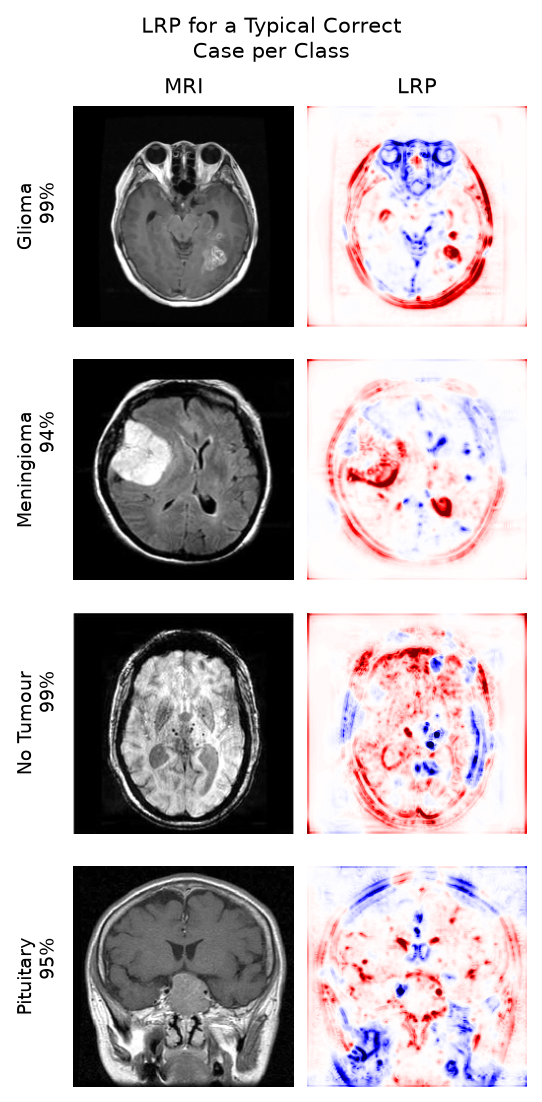

In [4]:
fig, axes = plt.subplots(len(CLASSES), 2, figsize=(FIGURE_WIDTH * 0.5, FIGURE_WIDTH + 0.3))
for row, (label, i) in zip(axes, cases.items(), strict=True):
    image = normalise(test_images[i])
    show_image(row[0], image)
    show_lrp(row[1], lrp_heatmap(lrp(model, image, int(test.loc[i, "predicted"]))))
    row[0].text(
        -0.06,
        0.5,
        f"{CLASS_LABELS[label]}\n{test.loc[i, 'confidence']:.0%}",
        transform=row[0].transAxes,
        rotation=90,
        ha="right",
        va="center",
    )
axes[0, 0].set_title("MRI")
axes[0, 1].set_title("LRP")
fig.suptitle("LRP for a Typical Correct\nCase per Class")
save_figure(fig, "06_lrp_cases")

<a id="sec-contrast"></a>

## 6. Class-contrastive explanation

- LRP explains one class at a time, so one scan can be explained for the predicted class and for the runner-up.
- Where the two maps differ shows what separates the two diagnoses in the model's view.

- **Main case:** `meningioma_tumor/image(88).jpg`, chosen by the case rule of [Section 5](#sec-local); the tumour is large and clearly visible, so the explanation can be checked by eye. It is reused in [notebook 07](07_gradcam.ipynb#sec-main), the report and the slides.
- **Result:** Meningioma 94.3%, runner-up No Tumour 5.6%. The tumour edge that is red for Meningioma (b) is blue for No Tumour (c), and so is the ventricle spot.
- **Implication:** the decision between the two diagnoses rests on the tumour boundary; the same pixels count for one class and against the other.

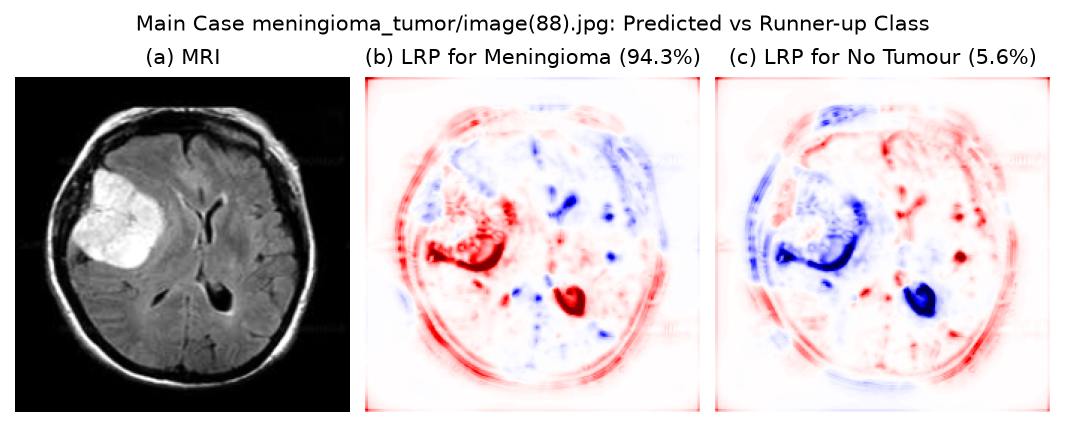

In [5]:
MAIN_CLASS = "meningioma_tumor"
main = cases[MAIN_CLASS]
image = normalise(test_images[main])
ranked = probabilities[main].argsort()[::-1]
fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, FIGURE_WIDTH / 3 + 0.4))
show_image(axes[0], image)
axes[0].set_title("MRI")
for ax, target in zip(axes[1:], ranked[:2], strict=True):
    show_lrp(ax, lrp_heatmap(lrp(model, image, int(target))))
    ax.set_title(f"LRP for {LABELS[target]} ({probabilities[main, target]:.1%})")
label_panels(axes)
main_file = f"{test.loc[main, 'path'].parent.name}/{test.loc[main, 'path'].name}"
fig.suptitle(f"Main Case {main_file}: Predicted vs Runner-up Class")
save_figure(fig, "06_lrp_contrast")

<a id="sec-takeaways"></a>

## 7. Key takeaways

1. **The provided LRP code works after small fixes** ([Section 2](#sec-changes)): any class can be explained, the pixel layer uses the $z^\mathcal{B}$ rule and the model is in evaluation mode.
2. **The implementation checks out, the method less so** ([Section 4](#sec-checks)): relevance is stable and agrees broadly with Captum (rank correlation 0.553), but the maps survive randomisation (0.690), so they partly show image structure; a second method is needed ([notebook 07](07_gradcam.ipynb)).
3. **LRP finds clear lesions** ([Section 5](#sec-local)): the glioma and the meningioma edge, but also the skull ring; the pituitary tumour is not marked.
4. **Class-contrastive maps help** ([Section 6](#sec-contrast)): for the main case, the tumour edge supports Meningioma and counts against No Tumour.

<a id="sec-references"></a>

## 8. References

Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). Sanity checks for saliency maps. *Advances in Neural Information Processing Systems, 31*, 9505-9515. https://doi.org/10.48550/arXiv.1810.03292

Bach, S., Binder, A., Montavon, G., Klauschen, F., Müller, K.-R., & Samek, W. (2015). On pixel-wise explanations for non-linear classifier decisions by layer-wise relevance propagation. *PLOS ONE, 10*(7), e0130140. https://doi.org/10.1371/journal.pone.0130140

deepfindr. (2021). *xai-series* [Computer software]. GitHub. https://github.com/deepfindr/xai-series

Kokhlikyan, N., Miglani, V., Martin, M., Wang, E., Alsallakh, B., Reynolds, J., Melnikov, A., Kliushkina, N., Araya, C., Yan, S., & Reblitz-Richardson, O. (2020). *Captum: A unified and generic model interpretability library for PyTorch*. arXiv. https://doi.org/10.48550/arXiv.2009.07896

Montavon, G., Binder, A., Lapuschkin, S., Samek, W., & Müller, K.-R. (2019). Layer-wise relevance propagation: An overview. In W. Samek, G. Montavon, A. Vedaldi, L. K. Hansen, & K.-R. Müller (Eds.), *Explainable AI: Interpreting, explaining and visualizing deep learning* (pp. 193-209). Springer. https://doi.org/10.1007/978-3-030-28954-6_10

Sixt, L., Granz, M., & Landgraf, T. (2020). When explanations lie: Why many modified BP attributions fail. *Proceedings of the 37th International Conference on Machine Learning, PMLR 119*, 9046-9057. https://proceedings.mlr.press/v119/sixt20a.html